# In-class work 4. Knowledge in a model, and a model in the plant

Industrial AI, KBTU. Goes with Lecture 4.

The data set is **AI4I 2020** again, the milling machine from In-class works 1 and 2: 10 000
cycles, five sensors, 339 failures. We come back to it on purpose. Its documentation writes
down the physics that produced the failures, so here, and almost nowhere else, we can put what
an expert knows next to what a model learns and compare them line by line.

The plan:

1. knowledge written by hand: the failure rules of AI4I as a small expert system;
2. knowledge learned from data: a decision tree, and the thresholds it finds by itself;
3. four ways to hold knowledge (rules, a tree, weights, stored cases) on one table;
4. the model leaves the notebook: a pipeline object, a file on disk, a scoring function that
   checks its input, a stream of cycles, a sensor that drifts;
5. what goes into the handover note.

Run top to bottom with `Shift+Enter`. The whole notebook takes about 20 seconds.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import sklearn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


In [2]:
def load_ai4i():
    df = pd.read_csv(dataset_folder("ai4i") / "ai4i2020.csv", encoding="utf-8-sig")
    return df.rename(columns={
        "Product ID": "product", "Type": "type",
        "Air temperature [K]": "air", "Process temperature [K]": "process",
        "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque",
        "Tool wear [min]": "wear", "Machine failure": "failure"})


df = load_ai4i()
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df.shape)
print("failures:", df["failure"].sum(), "| by mode:", df[MODES].sum().to_dict())
df.head(3)

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
(10000, 14)
failures: 339 | by mode: {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}


,UDI,product,type,air,process,rpm,torque,wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0


From here on the columns have short names: `air` and `process` in kelvin, `rpm`, `torque` in
N·m, `wear` in minutes of tool use. `type` is the product quality variant, L, M or H.

There are five failure modes, and one cycle can have several.

| mode | name | how it is caused in this data set |
|---|---|---|
| `TWF` | tool wear failure | the tool is replaced or breaks at a random wear between 200 and 240 min |
| `HDF` | heat dissipation failure | air–process temperature difference below 8.6 K **and** speed below 1380 rpm |
| `PWF` | power failure | mechanical power below 3500 W or above 9000 W |
| `OSF` | overstrain failure | wear × torque above 11 000 min·N·m for L, 12 000 for M, 13 000 for H |
| `RNF` | random failure | 0.1 % chance in any cycle, whatever the sensors say |

The table is taken from the documentation of the data set (Matzka, 2020). For us it plays the
part of **expert knowledge**: what a process engineer would tell you after twenty years at
this machine.

---

# Part 1. Knowledge written by hand

## 1.1 An expert system in twelve lines

An expert system stores knowledge as **production rules**, *if* condition *then* conclusion.
A person writes the rules, so every alarm can name the rule that raised it.

The rules need three quantities the file does not have: the temperature difference, the
mechanical power and the strain. Physics gives them, the data does not:

$$\Delta T = T_{process} - T_{air}, \qquad P = M \omega = M \cdot \frac{2\pi n}{60}, \qquad S = t_{wear} \cdot M$$

Here $M$ is the torque in N·m and $n$ the speed in rpm, so $P$ comes out in watts. Each rule is
a region in the space of these quantities: HDF is a rectangle in $(\Delta T, n)$, PWF is
everything outside a band of $P$, OSF is a half-line of $S$. Keep the shapes in mind, they
decide which models can learn what in Part 3.

In [3]:
# min*N*m, from the documentation
STRAIN_LIMIT = {"L": 11_000, "M": 12_000, "H": 13_000}


def add_physics(d):
    d = d.copy()
    d["dT"] = d["process"] - d["air"]                          # K
    d["power"] = d["torque"] * d["rpm"] * 2 * np.pi / 60       # W

    # 1.0 = exactly at the limit of the product type
    limit = d["type"].map(STRAIN_LIMIT)
    d["strain_ratio"] = d["wear"] * d["torque"] / limit
    return d


def expert_rules(d):
    # one boolean column per rule; the name of the column is the explanation
    return pd.DataFrame({
        "HDF": (d["dT"] < 8.6) & (d["rpm"] < 1380),
        "PWF": (d["power"] < 3500) | (d["power"] > 9000),
        "OSF": d["strain_ratio"] > 1.0,
    }, index=d.index)


df = add_physics(df)
fired = expert_rules(df)
df["rule_alarm"] = fired.any(axis=1)

for mode in fired:
    disagree = (fired[mode] != df[mode].astype(bool)).sum()
    print(f"{mode}: rule fired {fired[mode].sum():4d} times, "
          f"true {mode} {df[mode].sum():4d}, disagreements {disagree}")

HDF: rule fired  115 times, true HDF  115, disagreements 0
PWF: rule fired   95 times, true PWF   95, disagreements 0
OSF: rule fired   98 times, true OSF   98, disagreements 0


Each of the three rules matches its label exactly: every HDF, PWF and OSF cycle in the file is
a cycle where the rule fires, and there are no others. No surprise, since the data were
*generated* by these rules. On a real machine the engineers' rules are only roughly right.

How many of the 339 failures do the rules explain together?

In [4]:
print(pd.crosstab(df["rule_alarm"], df["failure"],
                  rownames=["rules fire"], colnames=["failure"]))

missed = df[(df["failure"] == 1) & ~df["rule_alarm"]]
print(f"\nfailures the rules miss: {len(missed)}")
print("their modes:", missed[MODES].sum().to_dict())
print(f"no mode recorded at all: {(missed[MODES].sum(axis=1) == 0).sum()}")

twf_wear = missed.loc[missed["TWF"] == 1, "wear"]
print(f"\ntool wear of the missed TWF cycles: {twf_wear.min()}–{twf_wear.max()} min")

failure        0    1
rules fire           
False       9661   52
True           0  287

failures the rules miss: 52
their modes: {'TWF': 43, 'HDF': 0, 'PWF': 0, 'OSF': 0, 'RNF': 1}
no mode recorded at all: 9

tool wear of the missed TWF cycles: 198–246 min


The rules catch 287 of 339 failures with **zero** false alarms. They miss 52:

- **43 TWF**, tool wear failures. Once the wear passes about 200 minutes the tool breaks at a
  random moment. No sensor says *which* cycle it will be; the wear only says the window is
  open. A maintenance schedule ("change the tool at 200 min") handles this, a detector cannot;
- **one RNF**, a random failure, unpredictable by construction;
- **nine cycles** labelled as failures with no mode at all. That is label noise, and every real
  data set has some.

So even a perfect expert stops at 287 / 339 = 0.85. Keep the number: a model that learns from
these five sensors should not be expected to beat it.

---

# Part 2. Knowledge learned from data

## 2.1 A decision tree on the raw sensors

A decision tree is a set of if-then rules too, only the machine writes them. At each node it
tries every feature $j$ and every threshold $\theta$ and keeps the pair that leaves the two
children purest. With the Gini impurity of a node with failure share $p$,

$$G = 2p(1-p),$$

the tree picks the split that minimises $\frac{n_L}{n} G_L + \frac{n_R}{n} G_R$. $G$ is 0 for a
pure node and largest at $p = 0.5$. Each question has the form $x_j \le \theta$, so every leaf
is a box with sides parallel to the axes.

For everything below we split once: 70 % of the cycles to learn from, 30 % to check on, with
the same failure rate in both.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import precision_score, recall_score, f1_score

df["type_code"] = df["type"].map({"L": 0, "M": 1, "H": 2})
RAW = ["type_code", "air", "process", "rpm", "torque", "wear"]
y = df["failure"].to_numpy()
train, test = train_test_split(df.index, test_size=0.3, stratify=y, random_state=0)


def score(pred):
    yt = y[test]
    return {"precision": precision_score(yt, pred, zero_division=0),
            "recall": recall_score(yt, pred),
            "F1": f1_score(yt, pred),
            "false alarms": int(((pred == 1) & (yt == 0)).sum()),
            "missed": int(((pred == 0) & (yt == 1)).sum())}


# model name -> scores; a dict, so running a cell twice does not add rows twice
results = {}
rule_pred = df.loc[test, "rule_alarm"].astype(int).to_numpy()
results["expert rules"] = score(rule_pred)

for depth in [3, 5, 8, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0)
    tree.fit(df.loc[train, RAW], y[train])
    name = f"tree, raw, depth {depth}, {tree.get_n_leaves()} leaves"
    results[name] = score(tree.predict(df.loc[test, RAW]))
pd.DataFrame(results).T

,precision,recall,F1,false alarms,missed
expert rules,1.000,0.833,0.909,0.000,17.000
"tree, raw, depth 3, 8 leaves",0.720,0.176,0.283,7.000,84.000
"tree, raw, depth 5, 19 leaves",0.716,0.471,0.568,19.000,54.000
"tree, raw, depth 8, 57 leaves",0.846,0.647,0.733,12.000,36.000
"tree, raw, depth None, 135 leaves",0.676,0.676,0.676,33.000,33.000


In [6]:
tree3 = DecisionTreeClassifier(max_depth=3, random_state=0)
tree3.fit(df.loc[train, RAW], y[train])
print(export_text(tree3, feature_names=RAW, decimals=1))

|--- torque <= 63.5
|   |--- torque <= 13.2
|   |   |--- type_code <= 1.5
|   |   |   |--- class: 1
|   |   |--- type_code >  1.5
|   |   |   |--- class: 0
|   |--- torque >  13.2
|   |   |--- rpm <= 1380.5
|   |   |   |--- class: 0
|   |   |--- rpm >  1380.5
|   |   |   |--- class: 0
|--- torque >  63.5
|   |--- rpm <= 1292.0
|   |   |--- wear <= 160.5
|   |   |   |--- class: 0
|   |   |--- wear >  160.5
|   |   |   |--- class: 1
|   |--- rpm >  1292.0
|   |   |--- torque <= 64.6
|   |   |   |--- class: 1
|   |   |--- torque >  64.6
|   |   |   |--- class: 1



On the raw sensors the tree does badly: it catches 18 % of failures at depth 3, and at full
depth it grows 135 leaves and still misses a third. Its rules, `torque <= 13.2`,
`torque > 63.5`, `rpm <= 1292`, are pieces of the power band cut along the axes.

The geometry explains why. The power limits are curves $M n = \text{const}$, hyperbolas in the
$(n, M)$ plane, and a tree can only draw boxes with sides parallel to the axes. It covers a
hyperbola with a staircase, and every step costs a leaf and needs failures to learn it from.
In $(\log n, \log M)$ the same curve is the straight line $\log M + \log n = \text{const}$, but
it is still diagonal, so the staircase stays. What helps is a feature that turns the curve into
a threshold on a single axis.

## 2.2 The same tree on the physical quantities

So we give the tree the three quantities from Part 1 instead of the raw sensors.

In [7]:
PHYS = ["dT", "rpm", "power", "strain_ratio", "wear"]

for depth in [4, 5]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0)
    tree.fit(df.loc[train, PHYS], y[train])
    name = f"tree, physics, depth {depth}, {tree.get_n_leaves()} leaves"
    results[name] = score(tree.predict(df.loc[test, PHYS]))
pd.DataFrame(results).T

,precision,recall,F1,false alarms,missed
expert rules,1.000,0.833,0.909,0.000,17.000
"tree, raw, depth 3, 8 leaves",0.720,0.176,0.283,7.000,84.000
"tree, raw, depth 5, 19 leaves",0.716,0.471,0.568,19.000,54.000
"tree, raw, depth 8, 57 leaves",0.846,0.647,0.733,12.000,36.000
"tree, raw, depth None, 135 leaves",0.676,0.676,0.676,33.000,33.000
"tree, physics, depth 4, 5 leaves",1.000,0.559,0.717,0.000,45.000
"tree, physics, depth 5, 7 leaves",0.988,0.833,0.904,1.000,17.000


In [8]:
tree5 = DecisionTreeClassifier(max_depth=5, random_state=0)
tree5.fit(df.loc[train, PHYS], y[train])
print(export_text(tree5, feature_names=PHYS, decimals=2))

|--- strain_ratio <= 1.00
|   |--- power <= 9000.17
|   |   |--- power <= 3495.94
|   |   |   |--- class: 1
|   |   |--- power >  3495.94
|   |   |   |--- dT <= 8.65
|   |   |   |   |--- rpm <= 1380.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- rpm >  1380.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- dT >  8.65
|   |   |   |   |--- wear <= 202.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- wear >  202.50
|   |   |   |   |   |--- class: 0
|   |--- power >  9000.17
|   |   |--- class: 1
|--- strain_ratio >  1.00
|   |--- class: 1



Compare its thresholds with the documentation:

| the tree found | the documentation says |
|---|---|
| `strain_ratio > 1.00` | overstrain above the limit of the product type |
| `power <= 3495.94`, `power > 9000.17` | power below 3500 W or above 9000 W |
| `dT <= 8.65` together with `rpm <= 1380.00` | ΔT below 8.6 K and speed below 1380 rpm |

With seven leaves and 237 training failures the tree has **rediscovered the physics**. On the
test set it agrees with the expert rules almost exactly, with one extra false alarm. In the new
coordinates every failure region is a box again, the one shape a tree draws for free.

The work was split in two. The engineer knew *which quantities* matter (ΔT, power, strain),
and the data found *where the thresholds are*. Neither was enough alone: the raw tree had the
data without the quantities and got 18–65 %.

---

# Part 3. Four ways to hold knowledge

## 3.1 The same failures, four representations

Lecture 4 lists several forms of knowledge representation. Four of them we can run. Write one
cycle as a feature vector $\mathbf{x} \in \mathbb{R}^d$ and the training set as the matrix
$\mathbf{X} \in \mathbb{R}^{n \times d}$, a cycle per row.

| form | what is stored | how a new cycle $\mathbf{x}$ is judged | model here |
|---|---|---|---|
| production rules | if-then statements written by a person | the rules that fire | `expert_rules` |
| decision tree | if-then statements found in the data | the box $\mathbf{x}$ falls into | `DecisionTreeClassifier` |
| weights | a vector $\mathbf{w}$ and a number $b$ | $p = \sigma(\mathbf{w}^\top \mathbf{x} + b)$ | `LogisticRegression` |
| cases | the rows of $\mathbf{X}$ themselves | the labels of the $k$ rows nearest to $\mathbf{x}$ | `KNeighborsClassifier` |

The shape of what each form can say follows from the formula. Logistic regression says "fail"
when $\mathbf{w}^\top \mathbf{x} + b > 0$: one half of the space, cut by one hyperplane.
Nearest neighbours can draw any shape, but "nearest" means the distance
$\lVert \mathbf{x} - \mathbf{x}_i \rVert$, so everything depends on the units of the axes.

Semantic networks, frames and ontologies are the other forms from the lecture. They describe
*what the plant is made of* (this pump feeds that tank) rather than *what to decide*, and we
will not code them.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
forest = RandomForestClassifier(300, random_state=0, n_jobs=-1)

candidates = {
    "weights: logistic regression": logistic,
    "cases: 5 nearest neighbours": knn,
    "300 trees: random forest": forest,
}
for name, model in candidates.items():
    for cols, tag in [(RAW, "raw"), (PHYS, "physics")]:
        model.fit(df.loc[train, cols], y[train])
        results[f"{name}, {tag}"] = score(model.predict(df.loc[test, cols]))

pd.DataFrame(results).T

,precision,recall,F1,false alarms,missed
expert rules,1.000,0.833,0.909,0.000,17.000
"tree, raw, depth 3, 8 leaves",0.720,0.176,0.283,7.000,84.000
"tree, raw, depth 5, 19 leaves",0.716,0.471,0.568,19.000,54.000
"tree, raw, depth 8, 57 leaves",0.846,0.647,0.733,12.000,36.000
"tree, raw, depth None, 135 leaves",0.676,0.676,0.676,33.000,33.000
"tree, physics, depth 4, 5 leaves",1.000,0.559,0.717,0.000,45.000
"tree, physics, depth 5, 7 leaves",0.988,0.833,0.904,1.000,17.000
"weights: logistic regression, raw",0.818,0.265,0.400,6.000,75.000
"weights: logistic regression, physics",0.810,0.167,0.276,4.000,85.000
"cases: 5 nearest neighbours, raw",0.667,0.333,0.444,17.000,68.000


In [10]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logreg.fit(df.loc[train, PHYS], y[train])
w = pd.Series(logreg[-1].coef_[0], index=PHYS).sort_values()
print("logistic regression weights on standardised physics features:")
print(w.round(2).to_string())

# which failures does it catch? PWF split into its two ends
pred = logreg.predict(df.loc[test, PHYS])
t = df.loc[test]
groups = {"PWF, power < 3500 W": (t["PWF"] == 1) & (t["power"] < 3500),
          "PWF, power > 9000 W": (t["PWF"] == 1) & (t["power"] > 9000),
          "HDF": t["HDF"] == 1,
          "OSF": t["OSF"] == 1}
print()
print("caught by logistic regression on the test set:")
for name, mask in groups.items():
    print(f"  {name:20s} {pred[mask.to_numpy()].sum():3d} of {mask.sum()}")

logistic regression weights on standardised physics features:
wear           -0.990
dT             -0.760
power           1.200
rpm             1.330
strain_ratio    1.600

caught by logistic regression on the test set:
  PWF, power < 3500 W    2 of 10
  PWF, power > 9000 W    8 of 20
  HDF                    3 of 30
  OSF                   11 of 32


The table says three things.

1. **Logistic regression gets worse with the physics features** (recall 0.17). Its knowledge
   is the vector $\mathbf{w}$, and the sign of each weight is the whole story: `power` got
   +1.20, "more power, more risk". The power rule is a *band*, and too little power is as bad
   as too much. A band needs two parallel hyperplanes, $P < 3500$ and $P > 9000$, while the
   model has one. It catches 8 of 20 power failures at the high end and 2 of 10 at the low
   end. HDF is a corner, "this *and* that", which no single hyperplane can cut out either: 3 of
   30. The model can store a band only if someone hands it a feature like $|P - 6250|$, which
   turns the band back into a half-space.

   Look also at `wear`: −0.99, as if wear protected the tool. It does not. `wear` and
   `strain_ratio` move together, and the model split one effect between them with opposite
   signs. When two columns of $\mathbf{X}$ are nearly collinear, only a combination of their
   weights is pinned down by the data, and each weight alone stops meaning anything.
2. **Nearest neighbours improve a lot with physics** (0.33 → 0.58). Cases are compared by
   distance. In (ΔT, power, strain) two cycles are close when they are physically alike. In the
   raw axes two cycles with the same power, one fast and light, one slow and heavy, lie far
   apart, so the neighbours of a failure are often healthy cycles.
3. **The forest on physics equals one small tree** (0.82 against 0.83). 300 trees added nothing
   that seven leaves did not already say. When the knowledge is simple, ship the simple form:
   the shift engineer can print it and check it.

| form | can an engineer read it? | how you update it | what it needs |
|---|---|---|---|
| rules | yes, it is their text | edit a line | an expert |
| tree | yes, if small | retrain | labelled failures |
| weights | partly: sign and size | retrain | labelled failures, the right features |
| cases | no, but each decision points to similar past cycles | add cycles | a good distance |

**Why does the forest get no `StandardScaler` in front of it, while logistic regression and
nearest neighbours do?**

<details><summary>Answer</summary>

A split $x_j \le \theta$ looks at one column and only at the order of its values. Apply any
increasing map $f$ to that column, $ax + b$ with $a > 0$ or a logarithm, and the same training
rows fall on each side of the threshold $f(\theta)$. The Gini of every candidate split is the
same, so the tree chooses the same partition and only the printed thresholds change. On these
data trees of depth 3 and 5 give identical test predictions on raw, standardised and
log-transformed sensors; the full-depth tree differs on 3 or 4 of the 3000 test cycles, through
ties between equally good splits.

Nearest neighbours add squared differences of all columns, and the penalty of logistic
regression adds squared weights, so for them the units of each column change the answer.

</details>

---

# Part 4. The model leaves the notebook

So far everything has lived inside one Jupyter session. On a plant the model runs elsewhere:
on an edge PC next to the machine, on the SCADA server, inside a historian plug-in. It gets one
cycle at a time from a live data source, and nobody watches the cells.

## 4.1 One object, from raw readings to the decision

In the notebook we computed `dT`, `power` and `strain_ratio` in one cell and trained in
another. In production the two must travel together, or someone will feed raw sensors to a
model that expects physics. So the feature code moves to a **module file** next to the model,
and the model becomes one `Pipeline`. From now on that module is the only place where the
physics is written down; the scoring function in 4.3 uses it too.

In [11]:
Path("ai4i_features.py").write_text("""
import numpy as np
import pandas as pd

STRAIN_LIMIT = {"L": 11_000, "M": 12_000, "H": 13_000}     # min*N*m
FEATURES = ["dT", "rpm", "power", "strain_ratio", "wear"]


def physics(d):
    \"\"\"Raw readings (type, air, process, rpm, torque, wear) -> physical features.\"\"\"
    d = pd.DataFrame(d)
    out = pd.DataFrame(index=d.index)
    out["dT"] = d["process"] - d["air"]                        # K
    out["rpm"] = d["rpm"]
    out["power"] = d["torque"] * d["rpm"] * 2 * np.pi / 60     # W
    out["strain_ratio"] = d["wear"] * d["torque"] / d["type"].map(STRAIN_LIMIT)
    out["wear"] = d["wear"]
    return out[FEATURES]
""", encoding="utf-8")

import importlib
import ai4i_features
importlib.reload(ai4i_features)

from sklearn.preprocessing import FunctionTransformer

INPUTS = ["type", "air", "process", "rpm", "torque", "wear"]      # what the machine sends
features = FunctionTransformer(ai4i_features.physics)
tree = DecisionTreeClassifier(max_depth=5, random_state=0)
model = make_pipeline(features, tree)
model.fit(df.loc[train, INPUTS], y[train])
print(score(model.predict(df.loc[test, INPUTS])))

{'precision': 0.9883720930232558, 'recall': 0.8333333333333334, 'F1': 0.9042553191489362, 'false alarms': 1, 'missed': 17}


The numbers are those of the tree in 2.2, but the model now takes what the machine sends: the
product type and five raw readings.

Why a separate `.py` file? `joblib` saves the pipeline, but a function defined in a notebook
cell is saved by *name only*. On another computer that name does not exist and loading fails.
A function in a module is found by importing the module.

## 4.2 A file on disk, and a note that goes with it

In [12]:
import joblib
import json
import datetime

Path("models").mkdir(exist_ok=True)
joblib.dump(model, "models/ai4i_tree_v1.joblib")

test_scores = score(model.predict(df.loc[test, INPUTS]))

card = {
    "model": "ai4i_tree_v1",
    "task": "machine failure in the next cycle, AI4I milling machine",
    "inputs": INPUTS,
    "units": {"air": "K", "process": "K", "rpm": "1/min", "torque": "N*m", "wear": "min"},
    "trained_on": f"{len(train)} cycles, {int(y[train].sum())} failures",
    "test": {k: round(v, 3) for k, v in test_scores.items()},
    "does_not_detect": "TWF (random tool breakage, 200-240 min), RNF",
    "sklearn": sklearn.__version__,
    "created": datetime.date.today().isoformat(),
}
Path("models/ai4i_tree_v1.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
print(json.dumps(card, indent=2))

{
  "model": "ai4i_tree_v1",
  "task": "machine failure in the next cycle, AI4I milling machine",
  "inputs": [
    "type",
    "air",
    "process",
    "rpm",
    "torque",
    "wear"
  ],
  "units": {
    "air": "K",
    "process": "K",
    "rpm": "1/min",
    "torque": "N*m",
    "wear": "min"
  },
  "trained_on": "7000 cycles, 237 failures",
  "test": {
    "precision": 0.988,
    "recall": 0.833,
    "F1": 0.904,
    "false alarms": 1,
    "missed": 17
  },
  "does_not_detect": "TWF (random tool breakage, 200-240 min), RNF",
  "sklearn": "1.9.1",
  "created": "2026-11-25"
}


The JSON next to the model is its **model card**: what it predicts, from which inputs, in which
units, how good it was, and what it cannot do. Operators read the line `does_not_detect` first.

Now the real test. We load the file in a **different Python process**, the way a SCADA server
would, and score two cycles.

In [13]:
import subprocess

# a small script for a separate Python process: load the file, score two cycles
probe = '''
import joblib
import pandas as pd

m = joblib.load("models/ai4i_tree_v1.joblib")
columns = ["type", "air", "process", "rpm", "torque", "wear"]
cycles = [("L", 298.9, 309.1, 2861, 4.6, 143),
          ("M", 300.0, 310.0, 1500, 40.0, 20)]
print("fresh process says:", m.predict(pd.DataFrame(cycles, columns=columns)).tolist())
'''
out = subprocess.run([sys.executable, "-c", probe], capture_output=True, text=True)
print(out.stdout or out.stderr[-400:])

fresh process says: [1, 0]



The first cycle runs at 2861 rpm and 4.6 N·m, which is 1378 W, below the 3500 W floor: a power
failure. The second is an ordinary cycle. The fresh process knows nothing about this notebook
and still answers right, because it finds `ai4i_features.py` in the same folder.

## 4.3 A scoring function that checks its input

A model answers whatever numbers it gets. A thermocouple that fell off reads room temperature,
a Modbus register read as the wrong type gives 65 535, a new SCADA tag sends °C instead of K.
The model still prints a confident 0 or 1.

So we wrap the model in a function that checks the input first and says **why** it decided.
The expert rules go in front of the model: when one fires, the reason is a sentence an operator
understands. The rules read the features from `ai4i_features.physics`, the same code the model
uses, so the two cannot drift apart.

In [14]:
LIMITS = {"air": (290, 310), "process": (300, 320), "rpm": (1000, 3000),
          "torque": (0, 100), "wear": (0, 260)}


def answer(decision, reason=""):
    return {"decision": decision, "reason": reason}


def score_cycle(rec):
    # 1. input checks: refuse to decide on data that cannot be right
    if rec.get("type") not in ai4i_features.STRAIN_LIMIT:
        return answer("NO DECISION", f"unknown product type {rec.get('type')!r}")
    for tag, (lo, hi) in LIMITS.items():
        v = rec.get(tag)
        if v is None or not np.isfinite(v):
            return answer("NO DECISION", f"{tag} missing")
        if not lo <= v <= hi:
            return answer("NO DECISION", f"{tag} = {v} outside {lo}-{hi}")

    # 2. expert rules: physics we are sure about, with a readable reason
    x = pd.DataFrame([rec])[INPUTS]
    fired = expert_rules(ai4i_features.physics(x)).iloc[0]
    for rule, hit in fired.items():
        if hit:
            return answer("STOP", f"rule {rule}")

    # 3. the learned model for everything else
    p = model.predict_proba(x)[0, 1]
    if p >= 0.5:
        return answer("STOP", f"model, p = {p:.2f}")

    # 4. maintenance knowledge: the tool-wear window cannot be predicted, only scheduled
    if rec["wear"] >= 200:
        return answer("CHANGE TOOL", f"wear {rec['wear']} min, TWF window 200-240")
    return answer("RUN")


# type, air, process, rpm, torque, wear
rows = [
    ("L", 298.9, 309.1, 2861, 4.6, 143),        # power below the floor
    ("M", 300.0, 310.0, 1500, 40.0, 20),        # an ordinary cycle
    ("M", 300.0, 310.0, 1500, 40.0, 215),       # a worn tool
    ("L", 26.8, 36.9, 1500, 40.0, 20),          # temperatures in °C
    ("L", 300.0, 310.0, 65535, 40.0, 20),       # a bad Modbus register
    ("H", 300.0, np.nan, 1500, 40.0, 20),       # a lost reading
]
examples = [dict(zip(INPUTS, row)) for row in rows]
for rec in examples:
    print(score_cycle(rec))

{'decision': 'STOP', 'reason': 'rule PWF'}
{'decision': 'RUN', 'reason': ''}
{'decision': 'CHANGE TOOL', 'reason': 'wear 215 min, TWF window 200-240'}
{'decision': 'NO DECISION', 'reason': 'air = 26.8 outside 290-310'}
{'decision': 'NO DECISION', 'reason': 'rpm = 65535 outside 1000-3000'}
{'decision': 'NO DECISION', 'reason': 'process missing'}


Six cycles take six different paths through the function. The fourth is the Celsius mix-up
from In-class work 2: 26.8 °C is 300 K. Without the check the model would see ΔT = 10.1 K, a
healthy value, and say RUN. Here it refuses.

`NO DECISION` is a legitimate output. On a plant it reaches the operator's screen as a sensor
fault, and the machine keeps its last safe state.

## 4.4 A stream of cycles, and a sensor that drifts

Now we run the function the way the plant would, one cycle at a time in time order. We take
the last 3000 cycles of the file and, from cycle 1500 on, add **+2 K to the air temperature
sensor**. That is a typical calibration drift: a thermocouple junction ages, or the sensor is
moved closer to a warm motor. Nothing else changes, and the machine is exactly as healthy as
before.

In [15]:
import time

stream = df.iloc[-3000:][INPUTS + ["failure"]].reset_index(drop=True)
drifted = stream.copy()
drifted.loc[1500:, "air"] += 2.0          # the air sensor starts reading 2 K high

records = drifted[INPUTS].to_dict("records")
t0 = time.perf_counter()
decisions = [score_cycle(r) for r in records]
ms = (time.perf_counter() - t0) / len(drifted) * 1000
drifted["decision"] = [d["decision"] for d in decisions]
drifted["reason"] = [d["reason"] for d in decisions]
drifted["dT"] = drifted["process"] - drifted["air"]

print(f"{ms:.1f} ms per cycle, one cycle at a time")
for half, part in [("before drift", drifted[:1500]), ("after drift ", drifted[1500:])]:
    stops = part["decision"] == "STOP"
    real = part.loc[stops, "failure"].sum()
    by_hdf = (part["reason"] == "rule HDF").sum()
    print(f"{half}: STOP {stops.sum():3d}, of them real failures {real:3d}, "
          f"HDF rule {by_hdf:3d}")

4.2 ms per cycle, one cycle at a time
before drift: STOP  24, of them real failures  24, HDF rule   0
after drift : STOP  54, of them real failures  21, HDF rule  27


A few milliseconds per cycle, the exact number depends on the computer, and most of it is
pandas and scikit-learn overhead on a one-row table. A machining cycle takes tens of seconds,
so speed is no problem here. Inside a PLC scan of 10 ms it would be, and there the tree would
be rewritten as seven `IF` lines of structured text.

The problem is in the counts after the drift. Before it, all 24 STOPs were real failures. After
it there are 54 STOPs and only 21 real ones: the HDF rule, perfect on clean data, fired 27
times on healthy cycles. A 2 K error in one sensor moves ΔT from 10 K towards 8 K, across the
8.6 K line. The rule is right and the input is wrong. **A model is only as good as the sensor
it reads, and the sensor's health is not in the training data.**

## 4.5 Watching the inputs, not only the outputs

How would anyone notice? The alarm rate climbs, but that has two explanations: the machine got
worse, or a sensor did. To tell them apart we need a monitor on the **input**.

A first idea: physics says ΔT sits near 10 K, so watch its running mean and complain when it
leaves the range it had before. We take that range from the first 7000 cycles of the file, the
ones that came *before* the stream.

In [16]:
win = 100
history = df.iloc[:7000]["dT"]                             # the plant before the stream
level = history.rolling(win).mean()
roll_dT = drifted["dT"].rolling(win).mean()

print("running mean of ΔT over the 7000 earlier cycles: "
      f"{level.min():.2f} to {level.max():.2f} K")
print("in the drifted stream:                           "
      f"{roll_dT.min():.2f} to {roll_dT.max():.2f} K")

running mean of ΔT over the 7000 earlier cycles: 7.77 to 11.92 K
in the drifted stream:                           7.88 to 11.50 K


The level monitor is blind. On this machine ΔT wanders between 7.8 and 11.8 K by itself: the
air temperature follows the workshop, and the process temperature follows the air with a lag.
A 2 K offset keeps the drifted mean inside the normal range.

What never happens naturally is a **jump**. Compare the mean of the last $w = 100$ cycles with
the mean of the $w$ before them:

$$D_t = \Big|\, \bar{x}_{(t-w,\, t]} - \bar{x}_{(t-2w,\, t-w]} \,\Big|.$$

If ΔT were independent noise with spread $\sigma$, each mean would scatter by $\sigma/\sqrt{w}$
and their difference by $\sigma\sqrt{2/w}$, about $0.14\,\sigma$ for $w = 100$. A slow wander
of the level barely moves $D_t$ either, because two neighbouring windows see almost the same
level. A sensor offset of $\delta$ adds the full $\delta$ to $D_t$ for the $w$ cycles after it.
So the window averages away the noise and the slow trend and leaves the step. In the 7000
earlier cycles $D_t$ never went above 0.84 K; the offset makes it 2 K in one go.

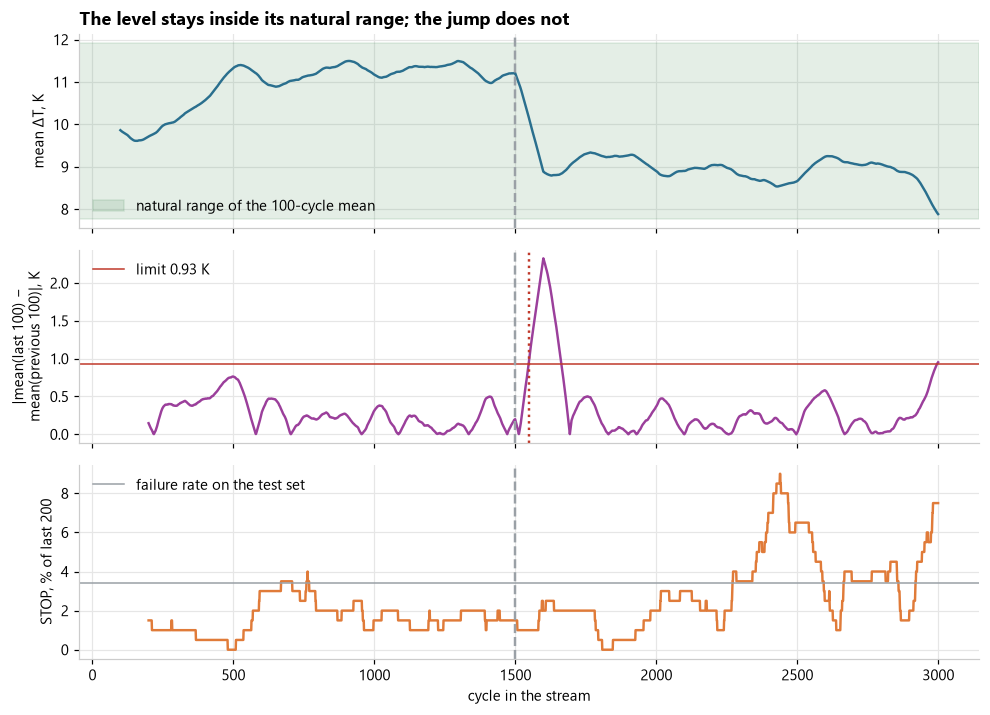

drift starts at cycle 1500, the step monitor flags it at cycle 1547 (47 cycles later); false flags before the drift: 0
flags after cycle 1700: 5, cycles 2995–2999


In [17]:
def step_stat(s, w=win):
    # D_t: the mean of the last w values against the mean of the w before them
    last = s.rolling(w).mean()
    previous = s.shift(w).rolling(w).mean()
    return (last - previous).abs()


limit = 1.1 * step_stat(history).max()         # 10 % above the worst natural step
step = step_stat(drifted["dT"])
first = int(np.argmax(step > limit))
roll_alarm = (drifted["decision"] == "STOP").rolling(200).mean() * 100

fig, ax = plt.subplots(3, 1, figsize=(9, 6.6), sharex=True)

ax[0].plot(roll_dT, color=BLUE)
ax[0].axhspan(level.min(), level.max(), color=GREEN, alpha=0.15,
              label="natural range of the 100-cycle mean")
ax[0].set(ylabel="mean ΔT, K",
          title="The level stays inside its natural range; the jump does not")
ax[0].legend(loc="lower left")

ax[1].plot(step, color=PURPLE)
ax[1].axhline(limit, color=RED, lw=1, label=f"limit {limit:.2f} K")
ax[1].axvline(first, color=RED, ls=":")
ax[1].set(ylabel="|mean(last 100) −\nmean(previous 100)|, K")
ax[1].legend(loc="upper left")

ax[2].plot(roll_alarm, color=ORANGE)
failure_rate = y[test].mean() * 100
ax[2].axhline(failure_rate, color=GREY, lw=1, label="failure rate on the test set")
ax[2].set(ylabel="STOP, % of last 200", xlabel="cycle in the stream")
ax[2].legend(loc="upper left")

for a in ax:
    a.axvline(1500, color=GREY, ls="--")
fig.tight_layout()
plt.show()

false_flags = int((step[:1500] > limit).sum())
print(f"drift starts at cycle 1500, the step monitor flags it at cycle {first} "
      f"({first - 1500} cycles later); false flags before the drift: {false_flags}")

late = np.flatnonzero(step[1700:] > limit) + 1700
late_text = f"flags after cycle 1700: {len(late)}"
if len(late):
    late_text += f", cycles {late.min()}–{late.max()}"
print(late_text)

The step monitor flags the drift 47 cycles after it starts and never fires before it. It knows
nothing about failures, only how fast ΔT is allowed to change. That is engineering knowledge
again: the process temperature follows the air slowly, so their difference cannot jump by 2 K
between two batches of cycles.

It is not perfect. In the last five cycles of the file it touches the limit again with no
sensor fault, because ΔT really does fall fast there, from 9 to 7.9 K. A flag is a request to
check the sensor and does not replace the check.

The alarm rate (bottom panel) is no help here. It stays at 1–2 % for 700 cycles after the drift,
and its later peaks mix real HDF failures with false ones.

What follows the flag is a procedure. The operator gets "air temperature sensor suspect",
maintenance checks the sensor against a handheld thermometer, and the model is **not** retrained
on the drifted data. Retraining would teach it that the new readings are normal and move the
HDF threshold by 2 K.

---

# Part 5. What goes with a model into production

A checklist. Each line is something that went wrong in this notebook, or will go wrong in the
first month on a plant.

| item | in this notebook |
|---|---|
| feature code in a module, not in a notebook cell | `ai4i_features.py` |
| one object from raw input to decision | `Pipeline(FunctionTransformer, tree)` |
| a model card: inputs, units, metrics, what it cannot do | `models/ai4i_tree_v1.json` |
| a load test in a fresh process | 4.2 |
| input checks and a `NO DECISION` answer | `score_cycle`, step 1 |
| known physics as rules in front of the model, with reasons | `score_cycle`, step 2 |
| what the model cannot do, handled by something else | tool change at 200 min |
| a monitor on the inputs that knows the physics | 4.5, the step monitor |
| a rule for when *not* to retrain | a drifted sensor |

## Further reading

- ONNX (Open Neural Network Exchange) is an open file format for trained models. The
  `skl2onnx` package converts a scikit-learn model, and ONNX Runtime runs it from C, C++, C#
  or Python on an edge PC without scikit-learn installed. A `FunctionTransformer` that calls
  Python code, like the physics step in 4.1, has no ONNX counterpart: those features have to be
  computed before the model or rewritten in ONNX operators.
- On a PLC there is usually no runtime for a model file. A small tree like the one in 2.2
  becomes nested `IF ... THEN` statements in IEC 61131-3 Structured Text and runs inside the
  scan cycle with no extra software.

## Questions to think about

1. The tree in 2.2 found `dT <= 8.65` where the documentation says 8.6. Why does a tree put
   its threshold halfway between two training values, and could it ever find exactly 8.6?
2. A colleague proposes to drop the expert rules from `score_cycle`, since the tree already
   found the same thresholds. What would the operator lose?
3. The depth-5 tree in 2.2 has a split `wear <= 202.50` where both leaves say `class: 0`.
   Gini decreased, yet no decision changed. How can that happen, and which failure mode is the
   tree reaching for?
4. The step monitor watches ΔT. Would it notice the air sensor drifting by 2 K slowly, over
   2000 cycles instead of at once? Use the formula for $D_t$ to estimate what it would see,
   and say what you would watch instead.